# Phase 5: Class Imbalance Handling

This notebook investigates strategies for handling the severe class imbalance
in the credit card fraud detection dataset.

The objectives are to:

- Load the training and validation splits created in Phase 3.
- Apply the selected Phase 4 feature-engineering configuration.
- Train class-weighted Logistic Regression, Random Forest, and LightGBM models.
- Train SMOTE-based Logistic Regression and Random Forest models.
- Evaluate every configuration on the validation set.
- Compare precision, recall, F1-score, PR-AUC, ROC-AUC, and false-positive
  behavior.
- Save imbalance-aware model artifacts and validation metrics.
- Update the model-comparison report.

The untouched test set is not used for training, model selection, threshold
tuning, or evaluation in this notebook.

In [1]:
import json
import logging
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbalancedPipeline

## Imports and configuration

This cell imports the libraries required for data handling, imbalance-aware
modeling, evaluation, and visualization.

It defines:

- Paths to the processed training and validation datasets.
- Output directories for figures, reports, and imbalance-model artifacts.
- A fixed random seed of `42`.
- An initial decision threshold of `0.5`.
- The selected feature configuration: `log_amount_and_time_hours`.

The `0.5` threshold is a baseline operating point, not an optimized threshold.
Threshold optimization is performed later using validation data only.

In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
IMBALANCE_MODELS_DIR = PROJECT_ROOT / "models" / "supervised" / "class_imbalance_models"

RANDOM_SEED = 42
DEFAULT_THRESHOLD = 0.5
FEATURE_CONFIGURATION = "log_amount_and_time_hours"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
IMBALANCE_MODELS_DIR.mkdir(parents=True, exist_ok=True)

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
)

logger = logging.getLogger(__name__)

logger.info("Project root: %s", PROJECT_ROOT)
logger.info("Selected feature configuration: %s", FEATURE_CONFIGURATION)

2026-11-01 10:15:35,910 | INFO | Project root: c:\Users\use\Desktop\Credit Card Fraud Detection
2026-11-01 10:15:35,912 | INFO | Selected feature configuration: log_amount_and_time_hours


## Load training and validation splits

This cell loads the training and validation feature matrices and target vectors
created during Phase 3.

It verifies that:

- Both feature and target files exist.
- Neither split is empty.
- Feature and target row counts match.
- Class counts are recorded for each split.

Only training and validation data are loaded. The test set remains untouched.

In [3]:
def load_split(
    feature_path: Path,
    target_path: Path,
) -> tuple[pd.DataFrame, pd.Series]:
    """Load a feature matrix and target vector from Parquet files."""
    if not feature_path.exists():
        raise FileNotFoundError(f"Feature file not found: {feature_path}")

    if not target_path.exists():
        raise FileNotFoundError(f"Target file not found: {target_path}")

    features = pd.read_parquet(feature_path)
    target_dataframe = pd.read_parquet(target_path)

    if features.empty or target_dataframe.empty:
        raise ValueError("Loaded split is empty.")

    target_column = target_dataframe.columns[0]
    target = target_dataframe[target_column]

    if len(features) != len(target):
        raise ValueError("Feature and target row counts do not match.")

    return features, target


X_train, y_train = load_split(
    feature_path=DATA_PROCESSED_DIR / "train" / "X_train.parquet",
    target_path=DATA_PROCESSED_DIR / "train" / "y_train.parquet",
)

X_validation, y_validation = load_split(
    feature_path=DATA_PROCESSED_DIR / "validation" / "X_validation.parquet",
    target_path=DATA_PROCESSED_DIR / "validation" / "y_validation.parquet",
)

logger.info("Training features: %s", X_train.shape)
logger.info("Validation features: %s", X_validation.shape)
logger.info("Training class counts: %s", y_train.value_counts().sort_index().to_dict())
logger.info(
    "Validation class counts: %s",
    y_validation.value_counts().sort_index().to_dict(),
)

2026-11-01 10:15:41,532 | INFO | Training features: (198608, 30)
2026-11-01 10:15:41,534 | INFO | Validation features: (42559, 30)
2026-11-01 10:15:41,540 | INFO | Training class counts: {0: 198277, 1: 331}
2026-11-01 10:15:41,545 | INFO | Validation class counts: {0: 42488, 1: 71}


## Apply the selected feature configuration

This cell applies the feature-engineering configuration selected in Phase 4:

```text
log_amount_and_time_hours
```

It adds:

- `Amount_log1p`: a zero-safe logarithmic transformation of `Amount`.
- `Time_hours`: elapsed transaction time converted from seconds to hours.

The same transformation is applied independently to the training and
validation sets. The cell also verifies that both datasets have identical
feature columns and that the `Class` target column is not present in the
feature matrices.

In [4]:
def add_log_amount_feature(features: pd.DataFrame) -> pd.DataFrame:
    """Add a zero-safe logarithmic transformation of Amount."""
    if "Amount" not in features.columns:
        raise ValueError("Required column 'Amount' is missing.")

    if (features["Amount"] < 0).any():
        raise ValueError("Negative Amount values found; log1p is not appropriate.")

    transformed = features.copy()
    transformed["Amount_log1p"] = np.log1p(transformed["Amount"])
    return transformed


def add_elapsed_time_hours_feature(features: pd.DataFrame) -> pd.DataFrame:
    """Add elapsed transaction time expressed in hours."""
    if "Time" not in features.columns:
        raise ValueError("Required column 'Time' is missing.")

    transformed = features.copy()
    transformed["Time_hours"] = transformed["Time"] / 3600.0
    return transformed


def apply_selected_feature_configuration(
    features: pd.DataFrame,
    configuration_name: str,
) -> pd.DataFrame:
    """Apply the selected Phase 4 feature-engineering configuration."""
    if configuration_name != "log_amount_and_time_hours":
        raise ValueError(
            "This notebook expects the selected Phase 4 configuration: "
            "'log_amount_and_time_hours'."
        )

    transformed = add_log_amount_feature(features)
    transformed = add_elapsed_time_hours_feature(transformed)

    if "Class" in transformed.columns:
        raise ValueError("Target leakage detected in engineered features.")

    return transformed


X_train_engineered = apply_selected_feature_configuration(
    features=X_train,
    configuration_name=FEATURE_CONFIGURATION,
)

X_validation_engineered = apply_selected_feature_configuration(
    features=X_validation,
    configuration_name=FEATURE_CONFIGURATION,
)

if list(X_train_engineered.columns) != list(X_validation_engineered.columns):
    raise ValueError("Training and validation feature columns do not match.")

logger.info("Engineered training features: %s", X_train_engineered.shape)
logger.info("Engineered validation features: %s", X_validation_engineered.shape)

2026-11-01 10:15:47,320 | INFO | Engineered training features: (198608, 32)
2026-11-01 10:15:47,323 | INFO | Engineered validation features: (42559, 32)


## Define evaluation metrics

This cell defines an evaluation function using metrics appropriate for highly
imbalanced fraud detection.

For each experiment, it calculates:

- Precision.
- Recall.
- F1-score.
- PR-AUC.
- ROC-AUC.
- False-positive rate.
- True positives, false positives, true negatives, and false negatives.
- Number of transactions flagged.

PR-AUC is particularly important because fraudulent transactions are extremely
rare. Accuracy alone would be misleading because a model could achieve high
accuracy by predicting nearly every transaction as legitimate.

In [5]:
def evaluate_classification_predictions(
    y_true: pd.Series,
    y_pred: np.ndarray,
    y_score: np.ndarray,
    threshold: float,
) -> dict:
    """Calculate metrics appropriate for highly imbalanced fraud detection."""
    confusion = confusion_matrix(y_true, y_pred, labels=[0, 1])
    true_negative, false_positive, false_negative, true_positive = confusion.ravel()

    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    false_positive_rate = (
        false_positive / (false_positive + true_negative)
        if (false_positive + true_negative) > 0
        else 0.0
    )

    has_both_classes = len(np.unique(y_true)) > 1

    return {
        "threshold": threshold,
        "precision": float(precision),
        "recall": float(recall),
        "f1_score": float(f1),
        "pr_auc": (
            float(average_precision_score(y_true, y_score))
            if has_both_classes
            else np.nan
        ),
        "roc_auc": (
            float(roc_auc_score(y_true, y_score))
            if has_both_classes
            else np.nan
        ),
        "false_positive_rate": float(false_positive_rate),
        "true_positives": int(true_positive),
        "false_positives": int(false_positive),
        "true_negatives": int(true_negative),
        "false_negatives": int(false_negative),
        "transactions_flagged": int(true_positive + false_positive),
    }

## Define class-imbalance experiments

This cell defines five imbalance-handling experiments:

1. **Logistic Regression with class weighting**
2. **Random Forest with class weighting**
3. **LightGBM with positive-class weighting**
4. **Logistic Regression with SMOTE**
5. **Random Forest with SMOTE**

Class weighting increases the importance of the minority fraud class during
training. LightGBM uses `scale_pos_weight`, calculated from the training class
counts.

SMOTE generates synthetic minority-class examples. It is applied only inside
the training pipeline, so validation data is never resampled.

These are experiments, not assumptions: each strategy is evaluated on the
validation set before any model is selected.

In [6]:
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
lightgbm_scale_pos_weight = negative_count / positive_count

logger.info(
    "LightGBM scale_pos_weight: %.4f",
    lightgbm_scale_pos_weight,
)


def create_class_weighted_logistic_regression() -> Pipeline:
    """Create a class-weighted Logistic Regression pipeline."""
    return Pipeline(
        steps=[
            ("standard_scaler", StandardScaler()),
            (
                "logistic_regression",
                LogisticRegression(
                    max_iter=1000,
                    class_weight="balanced",
                    random_state=RANDOM_SEED,
                    solver="lbfgs",
                ),
            ),
        ]
    )


def create_class_weighted_random_forest() -> Pipeline:
    """Create a class-weighted Random Forest pipeline."""
    return Pipeline(
        steps=[
            (
                "random_forest",
                RandomForestClassifier(
                    n_estimators=200,
                    max_depth=None,
                    min_samples_leaf=2,
                    class_weight="balanced",
                    n_jobs=-1,
                    random_state=RANDOM_SEED,
                ),
            ),
        ]
    )


def create_class_weighted_lightgbm() -> Pipeline:
    """Create a positive-class-weighted LightGBM pipeline."""
    return Pipeline(
        steps=[
            (
                "lightgbm",
                LGBMClassifier(
                    n_estimators=300,
                    learning_rate=0.05,
                    num_leaves=31,
                    max_depth=-1,
                    min_child_samples=20,
                    scale_pos_weight=lightgbm_scale_pos_weight,
                    random_state=RANDOM_SEED,
                    n_jobs=-1,
                    verbose=-1,
                ),
            ),
        ]
    )


def create_smote_logistic_regression() -> ImbalancedPipeline:
    """Create a Logistic Regression pipeline with training-only SMOTE."""
    return ImbalancedPipeline(
        steps=[
            ("standard_scaler", StandardScaler()),
            (
                "smote",
                SMOTE(
                    sampling_strategy="auto",
                    random_state=RANDOM_SEED,
                ),
            ),
            (
                "logistic_regression",
                LogisticRegression(
                    max_iter=1000,
                    random_state=RANDOM_SEED,
                    solver="lbfgs",
                ),
            ),
        ]
    )


def create_smote_random_forest() -> ImbalancedPipeline:
    """Create a Random Forest pipeline with training-only SMOTE."""
    return ImbalancedPipeline(
        steps=[
            (
                "smote",
                SMOTE(
                    sampling_strategy="auto",
                    random_state=RANDOM_SEED,
                ),
            ),
            (
                "random_forest",
                RandomForestClassifier(
                    n_estimators=200,
                    max_depth=None,
                    min_samples_leaf=2,
                    n_jobs=-1,
                    random_state=RANDOM_SEED,
                ),
            ),
        ]
    )


IMBALANCE_EXPERIMENTS = {
    "Logistic Regression | Class weighting": (
        create_class_weighted_logistic_regression,
        "Class weighting",
        "StandardScaler fitted on training data only",
    ),
    "Random Forest | Class weighting": (
        create_class_weighted_random_forest,
        "Class weighting",
        "No scaling required",
    ),
    "LightGBM | Positive-class weighting": (
        create_class_weighted_lightgbm,
        "Positive-class weighting",
        "No scaling required",
    ),
    "Logistic Regression | SMOTE": (
        create_smote_logistic_regression,
        "SMOTE",
        "StandardScaler and SMOTE fitted on training data only",
    ),
    "Random Forest | SMOTE": (
        create_smote_random_forest,
        "SMOTE",
        "SMOTE fitted on training data only",
    ),
}

logger.info("Defined imbalance experiments: %s", list(IMBALANCE_EXPERIMENTS))

2026-11-01 10:15:57,475 | INFO | LightGBM scale_pos_weight: 599.0242
2026-11-01 10:15:57,489 | INFO | Defined imbalance experiments: ['Logistic Regression | Class weighting', 'Random Forest | Class weighting', 'LightGBM | Positive-class weighting', 'Logistic Regression | SMOTE', 'Random Forest | SMOTE']


## Train and evaluate imbalance-aware models

This cell trains each imbalance-handling configuration on the engineered
training data and evaluates it on the validation set.

All experiments use:

- The same training data.
- The same validation data.
- The same feature configuration.
- The same initial decision threshold of `0.5`.

The results table compares precision, recall, F1-score, PR-AUC, ROC-AUC,
false-positive rate, flagged transactions, false positives, false negatives,
and training duration.

A strategy that improves recall may also increase false positives. Both
trade-offs must be considered together.

In [7]:
def train_and_evaluate_imbalance_experiment(
    experiment_name: str,
    pipeline_factory,
    imbalance_strategy: str,
    preprocessing_description: str,
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_validation: pd.DataFrame,
    y_validation: pd.Series,
) -> tuple[dict, Pipeline, np.ndarray]:
    """Train and evaluate one imbalance-handling configuration."""
    pipeline = pipeline_factory()

    training_start_time = time.time()
    pipeline.fit(X_train, y_train)
    training_duration = time.time() - training_start_time

    validation_scores = pipeline.predict_proba(X_validation)[:, 1]
    validation_predictions = (validation_scores >= DEFAULT_THRESHOLD).astype(int)

    metrics = evaluate_classification_predictions(
        y_true=y_validation,
        y_pred=validation_predictions,
        y_score=validation_scores,
        threshold=DEFAULT_THRESHOLD,
    )

    metrics.update(
        {
            "model": experiment_name.split(" | ")[0],
            "experiment_name": experiment_name,
            "feature_configuration": FEATURE_CONFIGURATION,
            "imbalance_strategy": imbalance_strategy,
            "preprocessing": preprocessing_description,
            "training_duration_seconds": training_duration,
            "feature_count": X_train.shape[1],
        }
    )

    return metrics, pipeline, validation_scores


imbalance_results = []
trained_imbalance_pipelines = {}
validation_scores_by_experiment = {}

for experiment_name, experiment_definition in IMBALANCE_EXPERIMENTS.items():
    pipeline_factory, imbalance_strategy, preprocessing_description = experiment_definition

    logger.info("Training imbalance experiment: %s", experiment_name)

    result, pipeline, validation_scores = train_and_evaluate_imbalance_experiment(
        experiment_name=experiment_name,
        pipeline_factory=pipeline_factory,
        imbalance_strategy=imbalance_strategy,
        preprocessing_description=preprocessing_description,
        X_train=X_train_engineered,
        y_train=y_train,
        X_validation=X_validation_engineered,
        y_validation=y_validation,
    )

    imbalance_results.append(result)
    trained_imbalance_pipelines[experiment_name] = pipeline
    validation_scores_by_experiment[experiment_name] = validation_scores

imbalance_results_dataframe = pd.DataFrame(imbalance_results)

imbalance_results_dataframe[
    [
        "experiment_name",
        "precision",
        "recall",
        "f1_score",
        "pr_auc",
        "roc_auc",
        "false_positive_rate",
        "transactions_flagged",
        "false_positives",
        "false_negatives",
        "training_duration_seconds",
    ]
]

2026-11-01 10:16:19,394 | INFO | Training imbalance experiment: Logistic Regression | Class weighting
2026-11-01 10:16:22,580 | INFO | Training imbalance experiment: Random Forest | Class weighting
2026-11-01 10:17:15,687 | INFO | Training imbalance experiment: LightGBM | Positive-class weighting
2026-11-01 10:17:24,355 | INFO | Training imbalance experiment: Logistic Regression | SMOTE
2026-11-01 10:17:29,340 | INFO | Training imbalance experiment: Random Forest | SMOTE


,experiment_name,precision,recall,f1_score,pr_auc,roc_auc,false_positive_rate,transactions_flagged,false_positives,false_negatives,training_duration_seconds
0,Logistic Regression | Class weighting,0.050602,0.887324,0.095745,0.706577,0.968105,0.027820,1245,1182,8,3.008589
1,Random Forest | Class weighting,0.963636,0.746479,0.841270,0.849424,0.945599,0.000047,55,2,18,52.725471
2,LightGBM | Positive-class weighting,0.076159,0.647887,0.136296,0.049930,0.817361,0.013133,604,558,25,8.269249
3,Logistic Regression | SMOTE,0.047800,0.887324,0.090713,0.709086,0.969187,0.029538,1318,1255,8,4.835792
4,Random Forest | SMOTE,0.888889,0.788732,0.835821,0.840678,0.961678,0.000165,63,7,15,277.364913


## Confusion matrices by imbalance strategy

This cell creates a confusion matrix for each imbalance-handling experiment at
the initial decision threshold of `0.5`.

Each matrix shows:

- True negatives.
- False positives.
- False negatives.
- True positives.

False positives are legitimate transactions incorrectly flagged for review.
False negatives are fraudulent transactions missed by the model. Comparing
these matrices helps show how each imbalance strategy changes the
precision-recall trade-off.

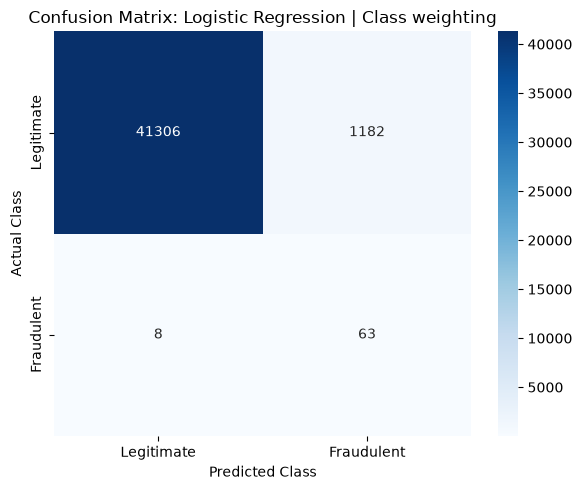

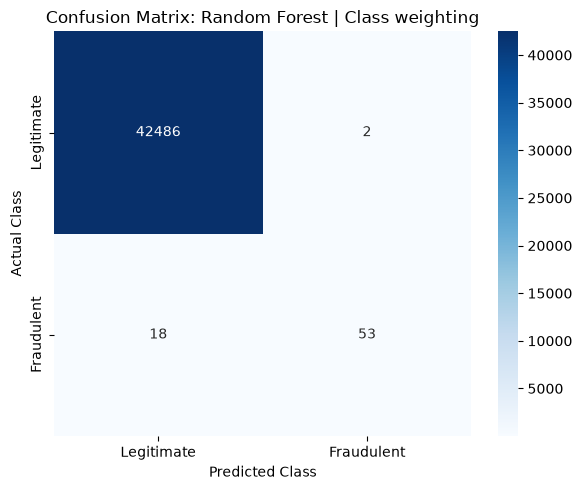

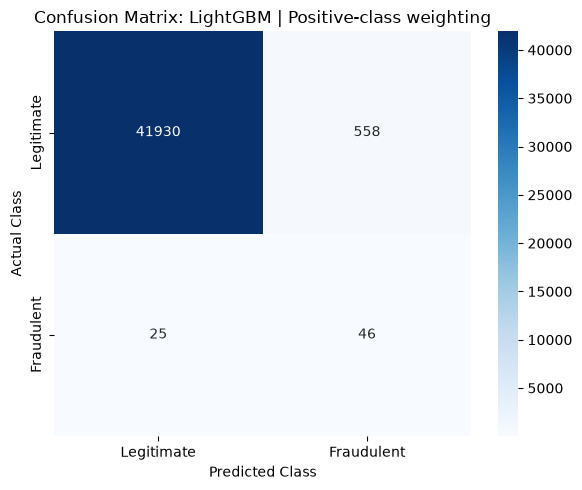

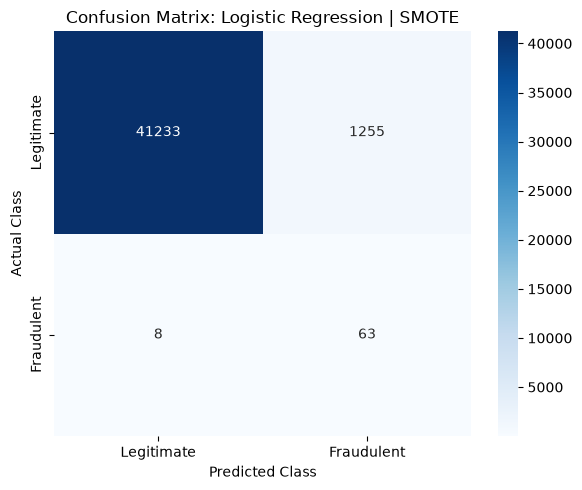

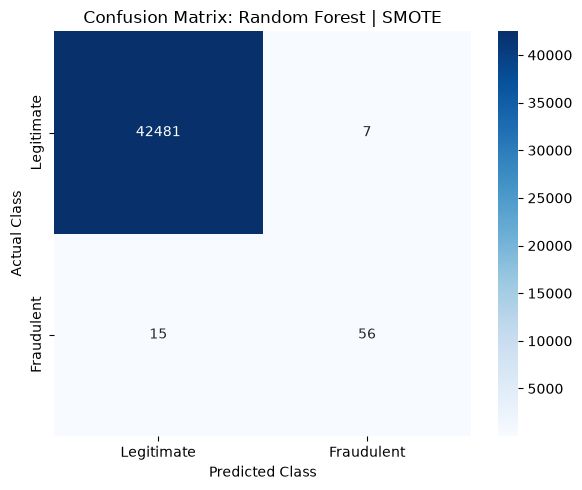

2026-11-01 10:23:55,278 | INFO | Class-imbalance confusion matrices generated.


In [8]:
def plot_confusion_matrix(
    y_true: pd.Series,
    y_score: np.ndarray,
    threshold: float,
    title: str,
    output_path: Path,
) -> None:
    """Plot a confusion matrix for a configured decision threshold."""
    predictions = (y_score >= threshold).astype(int)
    confusion = confusion_matrix(y_true, predictions, labels=[0, 1])

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        confusion,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Fraudulent"],
        yticklabels=["Legitimate", "Fraudulent"],
    )
    plt.title(title)
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


for experiment_name, validation_scores in validation_scores_by_experiment.items():
    safe_experiment_name = (
        experiment_name.lower()
        .replace(" | ", "_")
        .replace(" ", "_")
        .replace("-", "_")
    )

    plot_confusion_matrix(
        y_true=y_validation,
        y_score=validation_scores,
        threshold=DEFAULT_THRESHOLD,
        title=f"Confusion Matrix: {experiment_name}",
        output_path=FIGURES_DIR / f"class_imbalance_confusion_matrix_{safe_experiment_name}.png",
    )

logger.info("Class-imbalance confusion matrices generated.")

## Precision-recall and ROC curves

This cell plots validation precision-recall and ROC curves for all
imbalance-handling experiments.

The precision-recall curve is especially useful for highly imbalanced
classification because it focuses on performance for the minority fraud class.

The ROC curve shows the trade-off between true-positive rate and false-positive
rate across thresholds. A random classifier would follow the diagonal line.

These curves describe ranking performance across thresholds; they do not
replace evaluation at a specific operational threshold.

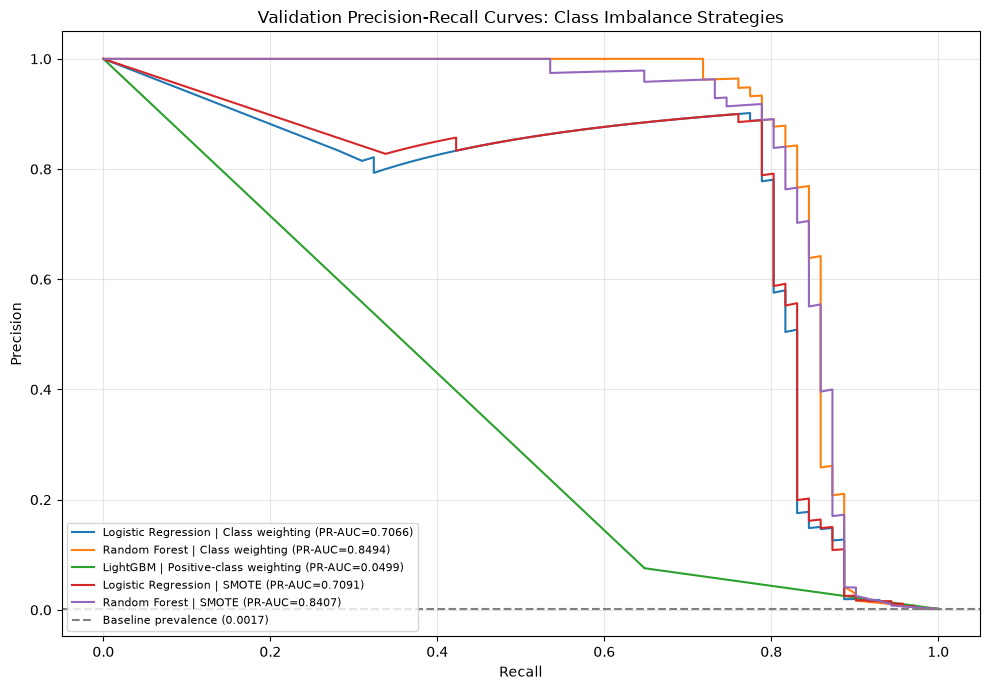

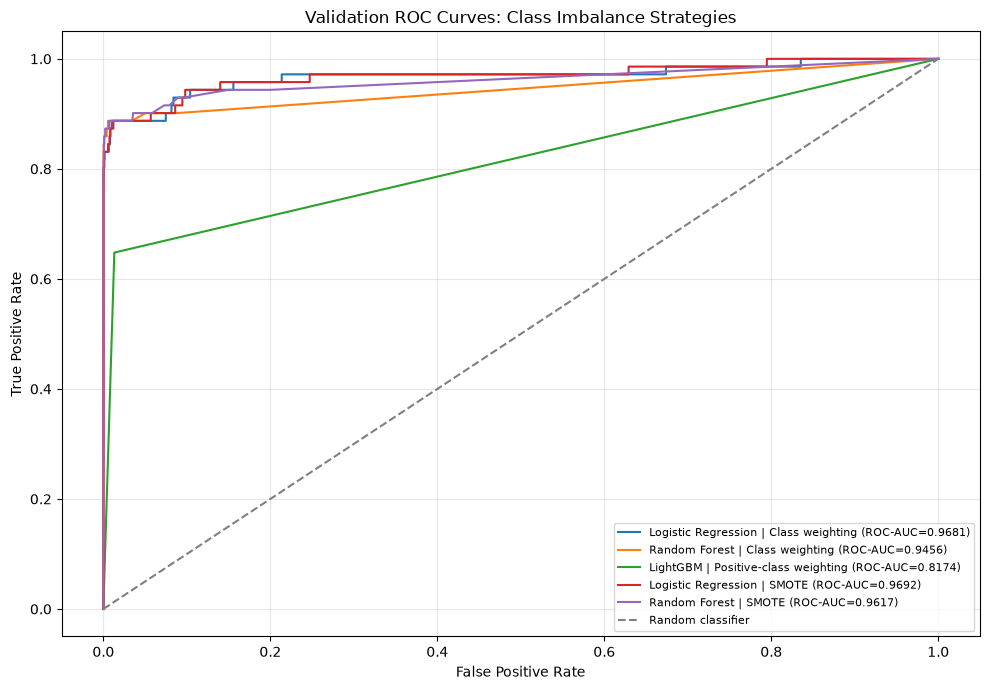

2026-11-01 10:24:09,142 | INFO | Class-imbalance PR and ROC curves generated.


In [9]:
def plot_precision_recall_curves(
    y_true: pd.Series,
    scores_by_experiment: dict[str, np.ndarray],
    output_path: Path,
) -> None:
    """Plot validation precision-recall curves for all imbalance experiments."""
    plt.figure(figsize=(10, 7))

    for experiment_name, scores in scores_by_experiment.items():
        precision_values, recall_values, _ = precision_recall_curve(
            y_true,
            scores,
        )
        pr_auc = average_precision_score(y_true, scores)

        plt.plot(
            recall_values,
            precision_values,
            label=f"{experiment_name} (PR-AUC={pr_auc:.4f})",
        )

    fraud_prevalence = y_true.mean()
    plt.axhline(
        fraud_prevalence,
        color="gray",
        linestyle="--",
        label=f"Baseline prevalence ({fraud_prevalence:.4f})",
    )

    plt.title("Validation Precision-Recall Curves: Class Imbalance Strategies")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.legend(fontsize=8)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


def plot_roc_curves(
    y_true: pd.Series,
    scores_by_experiment: dict[str, np.ndarray],
    output_path: Path,
) -> None:
    """Plot validation ROC curves for all imbalance experiments."""
    plt.figure(figsize=(10, 7))

    for experiment_name, scores in scores_by_experiment.items():
        false_positive_rate, true_positive_rate, _ = roc_curve(
            y_true,
            scores,
        )
        roc_auc = roc_auc_score(y_true, scores)

        plt.plot(
            false_positive_rate,
            true_positive_rate,
            label=f"{experiment_name} (ROC-AUC={roc_auc:.4f})",
        )

    plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random classifier")

    plt.title("Validation ROC Curves: Class Imbalance Strategies")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(fontsize=8)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


class_imbalance_pr_figure_path = (
    FIGURES_DIR / "class_imbalance_precision_recall_curves.png"
)
class_imbalance_roc_figure_path = (
    FIGURES_DIR / "class_imbalance_roc_curves.png"
)

plot_precision_recall_curves(
    y_true=y_validation,
    scores_by_experiment=validation_scores_by_experiment,
    output_path=class_imbalance_pr_figure_path,
)

plot_roc_curves(
    y_true=y_validation,
    scores_by_experiment=validation_scores_by_experiment,
    output_path=class_imbalance_roc_figure_path,
)

logger.info("Class-imbalance PR and ROC curves generated.")

## Save imbalance-aware model artifacts

This cell saves each trained imbalance-aware pipeline and its metadata.

For every experiment, the following artifacts are saved:

- Trained model pipeline.
- Experiment name.
- Model name and type.
- Feature configuration.
- Feature columns.
- Target column.
- Decision threshold.
- Imbalance strategy.
- Random seed.
- Preprocessing description.
- Validation metrics.

Each artifact is clearly marked as a Phase 5 imbalance-handling artifact, not
the final production model.

In [11]:
def save_imbalance_model_artifacts(
    experiment_name: str,
    pipeline: Pipeline,
    metrics: dict,
    output_directory: Path,
) -> dict:
    """Save one trained imbalance-aware pipeline and its metadata."""
    safe_experiment_name = (
        experiment_name.lower()
        .replace(" | ", "_")
        .replace(" ", "_")
        .replace("-", "_")
    )

    experiment_directory = output_directory / safe_experiment_name
    experiment_directory.mkdir(parents=True, exist_ok=True)

    model_path = experiment_directory / "model.joblib"
    metadata_path = experiment_directory / "metadata.json"

    joblib.dump(pipeline, model_path)

    metadata = {
        "experiment_name": experiment_name,
        "model_name": metrics["model"],
        "model_type": "supervised_classifier_with_imbalance_handling",
        "feature_configuration": FEATURE_CONFIGURATION,
        "feature_columns": list(X_train_engineered.columns),
        "target_column": "Class",
        "decision_threshold": DEFAULT_THRESHOLD,
        "imbalance_strategy": metrics["imbalance_strategy"],
        "random_seed": RANDOM_SEED,
        "preprocessing": metrics["preprocessing"],
        "validation_metrics": metrics,
        "artifact_note": (
            "This is a Phase 5 imbalance-handling artifact, not the final production model."
        ),
    }

    with metadata_path.open("w", encoding="utf-8") as file:
        json.dump(metadata, file, indent=2, default=str)

    return {
        "model_path": str(model_path),
        "metadata_path": str(metadata_path),
    }


imbalance_artifact_paths = {}

for experiment_name, pipeline in trained_imbalance_pipelines.items():
    matching_result = imbalance_results_dataframe[
        imbalance_results_dataframe["experiment_name"] == experiment_name
    ].iloc[0].to_dict()

    imbalance_artifact_paths[experiment_name] = save_imbalance_model_artifacts(
        experiment_name=experiment_name,
        pipeline=pipeline,
        metrics=matching_result,
        output_directory=IMBALANCE_MODELS_DIR,
    )

    logger.info(
        "Saved artifacts for %s: %s",
        experiment_name,
        imbalance_artifact_paths[experiment_name],
    )

2026-11-01 10:24:24,114 | INFO | Saved artifacts for Logistic Regression | Class weighting: {'model_path': 'c:\\Users\\use\\Desktop\\Credit Card Fraud Detection\\models\\supervised\\class_imbalance_models\\logistic_regression_class_weighting\\model.joblib', 'metadata_path': 'c:\\Users\\use\\Desktop\\Credit Card Fraud Detection\\models\\supervised\\class_imbalance_models\\logistic_regression_class_weighting\\metadata.json'}
2026-11-01 10:24:24,451 | INFO | Saved artifacts for Random Forest | Class weighting: {'model_path': 'c:\\Users\\use\\Desktop\\Credit Card Fraud Detection\\models\\supervised\\class_imbalance_models\\random_forest_class_weighting\\model.joblib', 'metadata_path': 'c:\\Users\\use\\Desktop\\Credit Card Fraud Detection\\models\\supervised\\class_imbalance_models\\random_forest_class_weighting\\metadata.json'}
2026-11-01 10:24:24,561 | INFO | Saved artifacts for LightGBM | Positive-class weighting: {'model_path': 'c:\\Users\\use\\Desktop\\Credit Card Fraud Detection\\mode

## Update the model-comparison report

This cell appends the class-imbalance experiment results to the existing
model-comparison CSV.

The combined report allows Phase 4 feature-engineering results, Phase 5
supervised baselines, and Phase 5 imbalance-handling experiments to be compared
using a consistent format.

No prior results are removed. New experiment rows are appended to the existing
comparison file.

In [12]:
def update_model_comparison_report(
    new_results: pd.DataFrame,
    comparison_path: Path,
) -> pd.DataFrame:
    """Append new experiment results to the existing comparison report."""
    if comparison_path.exists():
        existing_results = pd.read_csv(comparison_path)
    else:
        existing_results = pd.DataFrame()

    new_result_columns = list(new_results.columns)

    if not existing_results.empty:
        missing_columns = set(new_result_columns) - set(existing_results.columns)
        for column in missing_columns:
            existing_results[column] = np.nan

    combined_results = pd.concat(
        [existing_results[new_result_columns], new_results[new_result_columns]],
        ignore_index=True,
    )

    combined_results.to_csv(comparison_path, index=False)
    return combined_results


model_comparison_path = REPORTS_DIR / "model_comparison.csv"

updated_model_comparison = update_model_comparison_report(
    new_results=imbalance_results_dataframe,
    comparison_path=model_comparison_path,
)

logger.info(
    "Updated model comparison report: %s rows",
    len(updated_model_comparison),
)

2026-11-01 10:24:51,651 | INFO | Updated model comparison report: 11 rows


## Write class-imbalance report

This cell creates a Markdown report summarizing the class-imbalance
experiments.

The report includes:

- Feature configuration.
- Evaluation dataset.
- Decision threshold.
- Validation metrics for each experiment.
- Confusion-matrix components.
- Training duration.
- Preprocessing method.
- Interpretation and limitations.

The report clearly states that SMOTE and preprocessing were applied only during
training fit, that these are validation results, and that the test set remains
reserved for final evaluation.

In [13]:
def write_class_imbalance_report(
    results_dataframe: pd.DataFrame,
    report_path: Path,
) -> None:
    """Write a concise class-imbalance experiment report."""
    report_lines = [
        "# Class Imbalance Experiment Results",
        "",
        "## Scope",
        "",
        f"- Feature configuration: `{FEATURE_CONFIGURATION}`",
        "- Evaluation dataset: Validation set",
        f"- Decision threshold: {DEFAULT_THRESHOLD}",
        "- Test set: Not used in this phase",
        "- SMOTE and preprocessing were applied only during training fit",
        "",
        "## Validation Results",
        "",
    ]

    for _, row in results_dataframe.iterrows():
        report_lines.extend(
            [
                f"### {row['experiment_name']}",
                "",
                f"- Precision: {row['precision']:.4f}",
                f"- Recall: {row['recall']:.4f}",
                f"- F1-score: {row['f1_score']:.4f}",
                f"- PR-AUC: {row['pr_auc']:.4f}",
                f"- ROC-AUC: {row['roc_auc']:.4f}",
                f"- False-positive rate: {row['false_positive_rate']:.6f}",
                f"- Transactions flagged: {row['transactions_flagged']:,}",
                f"- True positives: {row['true_positives']}",
                f"- False positives: {row['false_positives']:,}",
                f"- False negatives: {row['false_negatives']}",
                f"- Training duration: {row['training_duration_seconds']:.2f} seconds",
                f"- Preprocessing: {row['preprocessing']}",
                "",
            ]
        )

    report_lines.extend(
        [
            "## Interpretation",
            "",
            "- These are validation results, not final generalization estimates.",
            "- PR-AUC is the primary ranking metric because fraud is extremely rare.",
            "- Class weighting and SMOTE may increase recall while reducing precision.",
            "- The best configuration must be selected using validation PR-AUC and operational false-positive trade-offs.",
            "- The untouched test set remains reserved for final evaluation.",
        ]
    )

    report_path.write_text("\n".join(report_lines), encoding="utf-8")


class_imbalance_report_path = REPORTS_DIR / "class_imbalance_report.md"

write_class_imbalance_report(
    results_dataframe=imbalance_results_dataframe,
    report_path=class_imbalance_report_path,
)

logger.info(
    "Class-imbalance report saved to: %s",
    class_imbalance_report_path,
)

2026-11-01 10:25:02,457 | INFO | Class-imbalance report saved to: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\class_imbalance_report.md


## Validate Phase 5 imbalance artifacts

This final cell verifies that all required Phase 5 imbalance outputs were
created:

- Precision-recall curve figure.
- ROC curve figure.
- Class-imbalance report.
- Updated model-comparison CSV.
- Trained model artifact for each imbalance experiment.
- Metadata file for each imbalance experiment.

If any required artifact is missing, the notebook raises an error instead of
silently claiming successful completion.

At this point, the class-imbalance phase is complete. The results provide a
comparison of class weighting and SMOTE strategies and help identify candidate
configurations for later hyperparameter optimization, threshold selection, and
final test evaluation.

In [14]:
required_imbalance_artifacts = [
    class_imbalance_pr_figure_path,
    class_imbalance_roc_figure_path,
    class_imbalance_report_path,
    model_comparison_path,
]

for artifact_paths in imbalance_artifact_paths.values():
    required_imbalance_artifacts.extend(
        [
            Path(artifact_paths["model_path"]),
            Path(artifact_paths["metadata_path"]),
        ]
    )

missing_artifacts = [
    path for path in required_imbalance_artifacts if not path.exists()
]

if missing_artifacts:
    raise FileNotFoundError(
        f"Missing Phase 5 imbalance artifacts: {[str(path) for path in missing_artifacts]}"
    )

logger.info("All required Phase 5 imbalance artifacts were generated successfully.")
print("Phase 5 class imbalance modelling completed successfully.")

2026-11-01 10:25:11,285 | INFO | All required Phase 5 imbalance artifacts were generated successfully.


Phase 5 class imbalance modelling completed successfully.
